# 05 · Analysis and reporting

Summarize pilot outcomes with condition-level counts, learner-paired primary contrasts, and a plot. The default results demonstrate the pipeline with synthetic data.

Run the setup cell first. See the repository README for ZIP and GitHub setup.

In [ ]:
from pathlib import Path
import subprocess
import sys
import tempfile
from zipfile import ZipFile

REPO_URL = ""
PROJECT_DIR = Path.cwd()

def find_project(directory):
    candidates = [directory, *sorted(path for path in directory.iterdir() if path.is_dir())]
    return next((path for path in candidates if (path / "src" / "pilot.py").is_file()), None)

project = find_project(PROJECT_DIR)
if project is None:
    if REPO_URL:
        project = Path(tempfile.mkdtemp(prefix="python-hci-")) / "repo"
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(project)], check=True)
    else:
        try:
            from google.colab import files
        except ImportError as exc:
            raise RuntimeError("Extract the repository and set PROJECT_DIR to its root.") from exc
        import io
        uploaded = files.upload()
        archives = [data for name, data in uploaded.items() if name.lower().endswith(".zip")]
        if len(archives) != 1:
            raise ValueError("Upload one project ZIP.")
        directory = Path(tempfile.mkdtemp(prefix="python-hci-"))
        with ZipFile(io.BytesIO(archives[0])) as archive:
            archive.extractall(directory)
        project = find_project(directory)
if project is None or not (project / "study" / "stimuli.json").is_file():
    raise FileNotFoundError("Project root not found. Use the ZIP supplied with these notebooks.")
sys.path.insert(0, str(project.resolve()))
from src import pilot
OUT = project / "outputs"
print("Project root:", project)

In [2]:
MODE = "demo"
RECORD_DIR = project / "private_data"
if MODE == "demo":
    records = pilot.read_json(project / "demo" / "synthetic_records.json")
elif MODE == "participant":
    records = [pilot.read_json(path) for path in sorted(RECORD_DIR.glob("*.json"))]
    if not records:
        raise FileNotFoundError(f"No response JSON files in {RECORD_DIR}.")
else:
    raise ValueError("Choose demo or participant mode.")

scored = pilot.score_records(records, MODE)
print(f"{MODE.upper()} · {len(records)} records · {len(scored)} scored trials")

DEMO · 12 records · 36 scored trials


In [3]:
from collections import defaultdict

metrics = {
    "rejected_inaccurate": "Rejected inaccurate claim",
    "accepted_accurate": "Accepted accurate claim",
    "initial_correct": "Initial answer correct",
    "final_correct": "Final answer correct",
    "wrong_to_right": "Wrong to right",
    "right_to_wrong": "Right to wrong",
    "transfer_correct": "Transfer correct",
    "evidence_opened": "Opened evidence",
    "source_link_opened": "Followed source link",
}
summary = []
for condition in pilot.CONDITIONS:
    rows = [row for row in scored if row["condition"] == condition]
    for key, label in metrics.items():
        values = [row[key] for row in rows if row[key] != ""]
        if values:
            summary.append({"condition": condition, "metric": label,
                            "count": sum(values), "total": len(values),
                            "proportion": round(sum(values) / len(values), 4)})

by_learner = defaultdict(dict)
for row in scored:
    by_learner[row["participant_id"]][row["condition"]] = row["rejected_inaccurate"]
contrasts = []
for higher, lower in [("B", "A"), ("C", "B")]:
    differences = [scores[higher] - scores[lower] for scores in by_learner.values()]
    contrasts.append({"contrast": f"{higher} − {lower}", "pairs": len(differences),
                      "improved": differences.count(1), "tied": differences.count(0),
                      "declined": differences.count(-1),
                      "percentage_points": round(100 * sum(differences) / len(differences), 1)})
for row in contrasts:
    print(row)
report_dir = OUT / MODE
pilot.write_csv(report_dir / "condition_summary.csv", summary)
pilot.write_csv(report_dir / "paired_primary_contrasts.csv", contrasts)

{'contrast': 'B − A', 'pairs': 12, 'improved': 2, 'tied': 8, 'declined': 2, 'percentage_points': 0.0}
{'contrast': 'C − B', 'pairs': 12, 'improved': 4, 'tied': 6, 'declined': 2, 'percentage_points': 16.7}


Outputs: outputs/demo


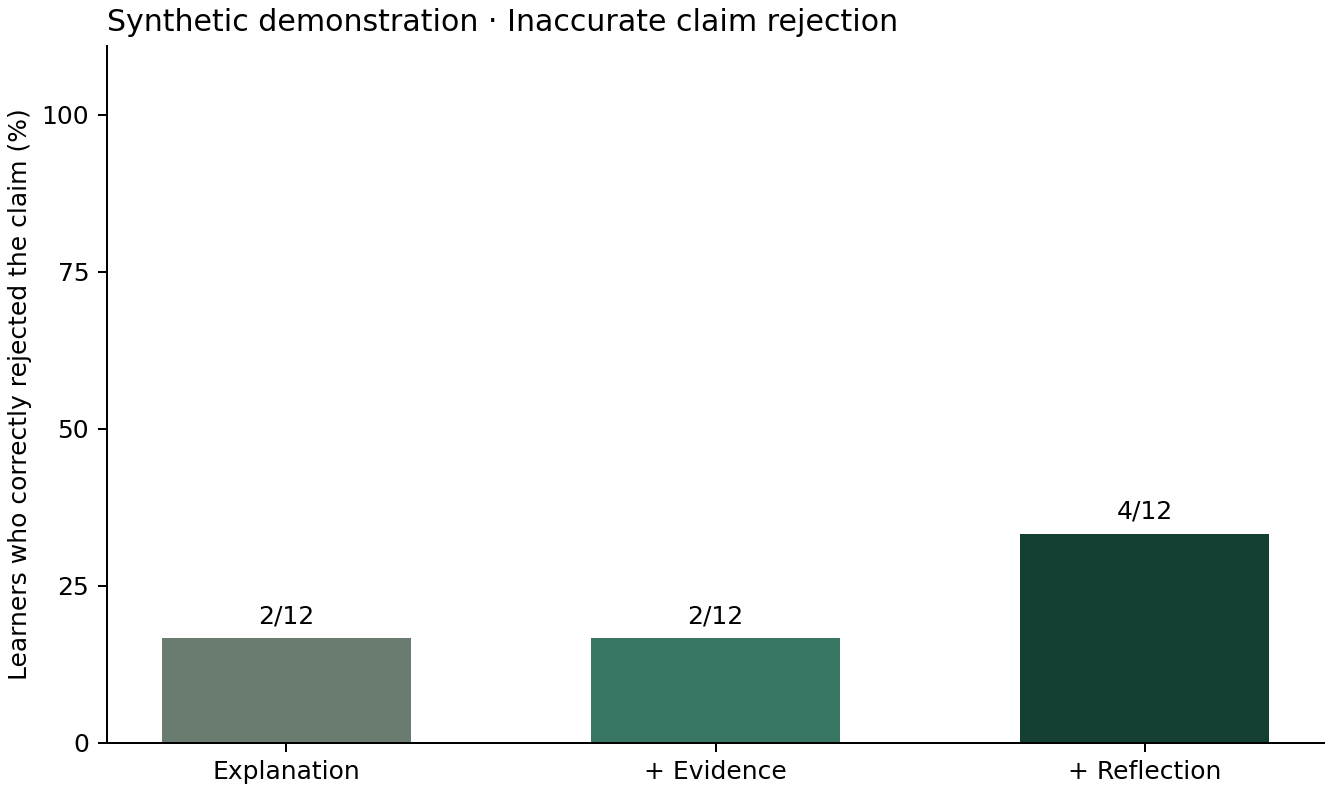

In [4]:
import matplotlib.pyplot as plt

primary = [row for row in summary if row["metric"] == "Rejected inaccurate claim"]
rates = [100 * row["count"] / row["total"] for row in primary]
labels = ["Explanation", "+ Evidence", "+ Reflection"]
fig, ax = plt.subplots(figsize=(7.4, 4.4), layout="constrained")
bars = ax.bar(labels, rates, color=["#6a7c70", "#397765", "#143f33"], width=0.58)
ax.bar_label(bars, [f"{row['count']}/{row['total']}" for row in primary], padding=4)
ax.set(ylim=(0, 111), yticks=[0, 25, 50, 75, 100],
       ylabel="Learners who correctly rejected the claim (%)")
prefix = "Synthetic demonstration · " if MODE == "demo" else ""
ax.set_title(prefix + "Inaccurate claim rejection", loc="left")
ax.spines[["top", "right"]].set_visible(False)
figure_path = report_dir / "claim_rejection.png"
fig.savefig(figure_path, dpi=180)
plt.show()
print("Outputs:", report_dir)

For the application or report, describe the implemented conditions and the study status. If you collect responses, report the actual number of complete sessions, any missing sessions, how the sequence balance was affected, and the primary contrast counts. A small immediate-transfer pilot supports descriptive findings. It cannot establish durable learning or support conclusions based on the synthetic demonstration.